# Task 1 — Detailed Exploratory Data Analysis (Cheater Detection)

**Problem**: Binary classification (`is_cheater` $\in \{0, 1\}$), evaluated by **Binary $F_2$ score** (recall is weighted 4× higher than precision).

This notebook walks through the data visually step-by-step, documenting each **discovered insight** and the exact **preprocessing / modeling decision** used in `task1.ipynb`.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def find_data_dir(subdir: str) -> str:
    for p in [os.path.join("..", "cpe342-kaggle-main", subdir), os.path.join("cpe342-kaggle-main", subdir)]:
        if os.path.isdir(p):
            return os.path.abspath(p)
    hits = glob.glob(f"/kaggle/input/**/{subdir}/train.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    raise FileNotFoundError(f"Dataset not found for {subdir}.")

DATA_DIR = find_data_dir("01_binary_classification")
tr = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
te = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
TARGET = "is_cheater"

lab = tr[tr[TARGET].notna()].reset_index(drop=True)
unl = tr[tr[TARGET].isna()].reset_index(drop=True)
y = lab[TARGET].astype(int).values

print(f"Train total: {tr.shape} | Labeled: {len(lab):,} | Unlabeled: {len(unl):,} | Test: {te.shape}")

Train total: (104000, 33) | Labeled: 90,816 | Unlabeled: 13,184 | Test: (25889, 32)


## Step 1: Dataset Structure, Unlabeled Rows & Class Balance

**What we check**: How many training rows have missing targets, and how imbalanced is `is_cheater`?

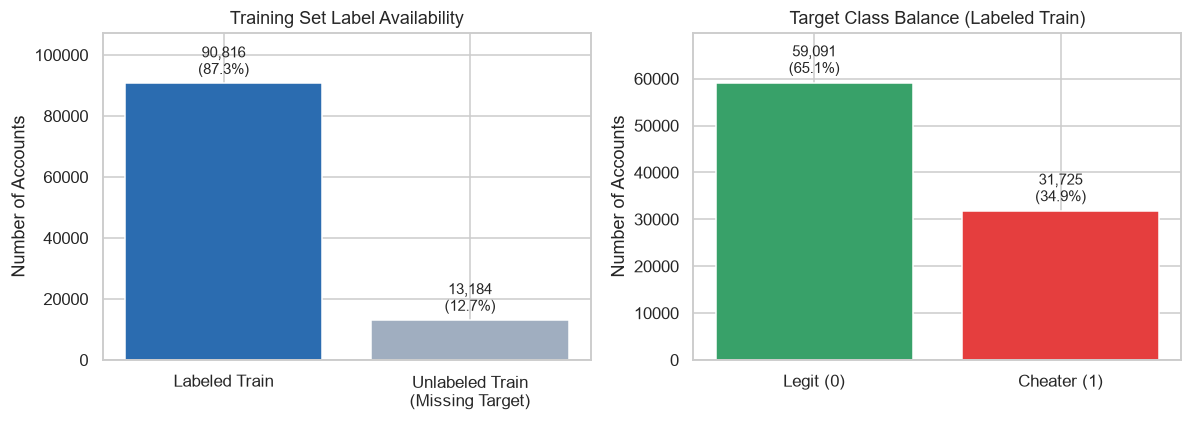

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Panel A: Labeled vs Unlabeled
counts_lbl = [len(lab), len(unl)]
bars = axes[0].bar(["Labeled Train", "Unlabeled Train\n(Missing Target)"], counts_lbl, color=["#2b6cb0", "#a0aec0"])
for b, v in zip(bars, counts_lbl):
    axes[0].text(b.get_x() + b.get_width()/2, v + 1500, f"{v:,}\n({v/len(tr)*100:.1f}%)", ha="center", va="bottom", fontsize=10)
axes[0].set_title("Training Set Label Availability")
axes[0].set_ylabel("Number of Accounts")
axes[0].set_ylim(0, max(counts_lbl) * 1.18)

# Panel B: Class Balance
cls_counts = [(y == 0).sum(), (y == 1).sum()]
bars2 = axes[1].bar(["Legit (0)", "Cheater (1)"], cls_counts, color=["#38a169", "#e53e3e"])
for b, v in zip(bars2, cls_counts):
    axes[1].text(b.get_x() + b.get_width()/2, v + 1200, f"{v:,}\n({v/len(y)*100:.1f}%)", ha="center", va="bottom", fontsize=10)
axes[1].set_title("Target Class Balance (Labeled Train)")
axes[1].set_ylabel("Number of Accounts")
axes[1].set_ylim(0, max(cls_counts) * 1.18)

plt.tight_layout()
plt.show()

**Insight 1**:
- **12.7%** of training rows (`13,184` rows) have no target label (`is_cheater = NaN`).
- Among labeled accounts, **34.9%** are cheaters (`1`) and **65.1%** are legitimate players (`0`).

**Decision**:
- Drop unlabeled rows from supervised training, but retain all training rows (`lab + unl`) when computing label-free statistics (medians, frequency tables, marginal priors).
- Because the metric is **Binary $F_2$** (which penalizes false negatives 4× more than false positives), tune the final classification threshold on OOF predictions (optimal predicted positive rate $\approx 60\%$, well above the 34.9% base rate).

## Step 2: Feature Signal vs. Pure Noise (Univariate ROC-AUC)

**What we check**: Which of the 31 raw features actually separate cheaters from legitimate players?

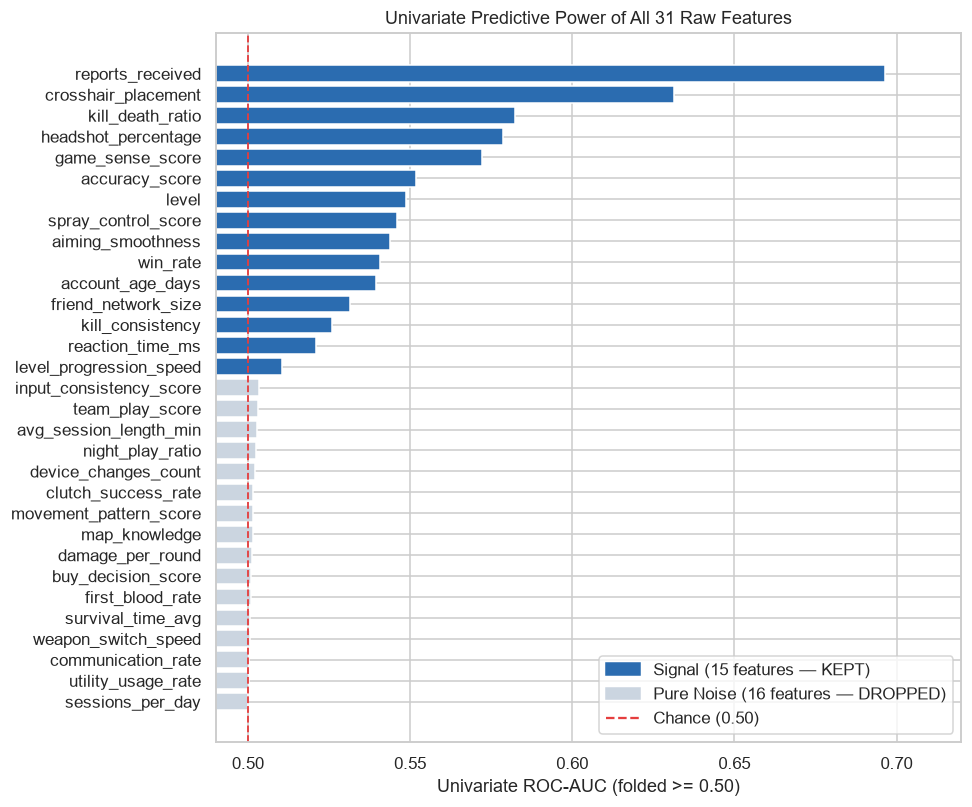

In [3]:
raw_cols = [c for c in lab.columns if c not in ("player_id", TARGET)]
aucs = {}
for c in raw_cols:
    ok = lab[c].notna().values
    a = roc_auc_score(y[ok], lab.loc[ok, c])
    aucs[c] = max(a, 1.0 - a)

auc_df = pd.DataFrame({"feature": list(aucs.keys()), "auc": list(aucs.values())}).sort_values("auc", ascending=True)
SIGNAL = [
    "kill_death_ratio", "headshot_percentage", "win_rate", "accuracy_score", "kill_consistency",
    "reaction_time_ms", "account_age_days", "level", "level_progression_speed", "friend_network_size",
    "reports_received", "aiming_smoothness", "spray_control_score", "game_sense_score", "crosshair_placement"
]
auc_df["group"] = np.where(auc_df["feature"].isin(SIGNAL), "Signal (15 features)", "Noise (16 features)")

fig, ax = plt.subplots(figsize=(9, 7.5))
colors = auc_df["group"].map({"Signal (15 features)": "#2b6cb0", "Noise (16 features)": "#cbd5e0"})
ax.barh(auc_df["feature"], auc_df["auc"], color=colors)
ax.axvline(0.50, color="#e53e3e", linestyle="--", linewidth=1.2, label="Random Chance (AUC = 0.50)")
ax.set_xlim(0.49, 0.72)
ax.set_xlabel("Univariate ROC-AUC (folded >= 0.50)")
ax.set_title("Univariate Predictive Power of All 31 Raw Features")
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="#2b6cb0", label="Signal (15 features — KEPT)"),
    Patch(color="#cbd5e0", label="Pure Noise (16 features — DROPPED)"),
    plt.Line2D([0], [0], color="#e53e3e", linestyle="--", label="Chance (0.50)"),
], loc="lower right")
plt.tight_layout()
plt.show()

**Insight 2**:
- Exactly **15 features** carry genuine predictive signal (univariate AUC `0.511 – 0.697`).
- The remaining **16 features** sit at pure random chance (`AUC = 0.500 – 0.503`).

**Decision**:
- Drop all 16 noise features before modeling to prevent tree splits and linear/neural models from fitting random noise.

## Step 3: Missing-Value Patterns & MCAR Verification

**What we check**: How prevalent are missing values across train and test, and does missingness itself correlate with cheating?

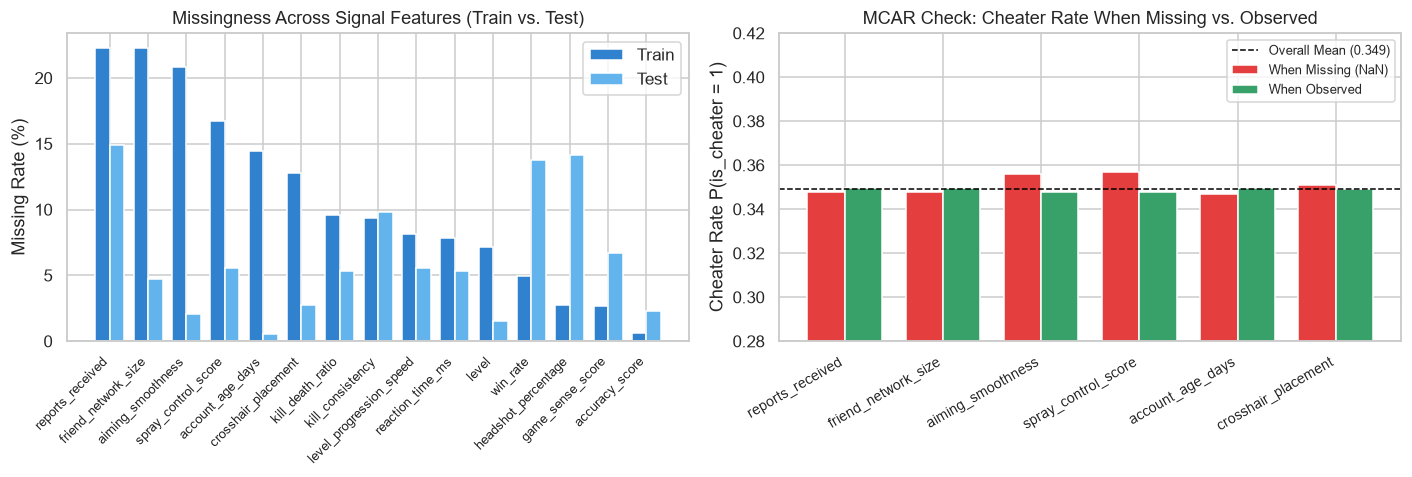

In [4]:
miss_tr = lab[SIGNAL].isna().mean() * 100
miss_te = te[SIGNAL].isna().mean() * 100
miss_df = pd.DataFrame({"Train %": miss_tr, "Test %": miss_te}).sort_values("Train %", ascending=False)

top_miss = miss_df.head(6).index.tolist()
p_nan = [y[lab[c].isna()].mean() for c in top_miss]
p_obs = [y[lab[c].notna()].mean() for c in top_miss]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel A: Missing % train vs test
x = np.arange(len(miss_df))
w = 0.38
axes[0].bar(x - w/2, miss_df["Train %"], width=w, label="Train", color="#3182ce")
axes[0].bar(x + w/2, miss_df["Test %"], width=w, label="Test", color="#63b3ed")
axes[0].set_xticks(x)
axes[0].set_xticklabels(miss_df.index, rotation=45, ha="right", fontsize=8.5)
axes[0].set_ylabel("Missing Rate (%)")
axes[0].set_title("Missingness Across Signal Features (Train vs. Test)")
axes[0].legend()

# Panel B: Cheater rate when NaN vs Observed (MCAR check)
x2 = np.arange(len(top_miss))
axes[1].bar(x2 - w/2, p_nan, width=w, label="When Missing (NaN)", color="#e53e3e")
axes[1].bar(x2 + w/2, p_obs, width=w, label="When Observed", color="#38a169")
axes[1].axhline(y.mean(), color="black", linestyle="--", linewidth=1, label=f"Overall Mean ({y.mean():.3f})")
axes[1].set_xticks(x2)
axes[1].set_xticklabels(top_miss, rotation=30, ha="right", fontsize=9)
axes[1].set_ylim(0.28, 0.42)
axes[1].set_ylabel("Cheater Rate P(is_cheater = 1)")
axes[1].set_title("MCAR Check: Cheater Rate When Missing vs. Observed")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

**Insight 3**:
- Train and test have identical missingness rates (up to **22.3%** missing on `reports_received` and `friend_network_size`).
- For every feature, $P(\text{cheater} \mid \text{NaN}) \approx P(\text{cheater} \mid \text{observed}) \approx 0.349$, proving missingness is **MCAR (Missing Completely At Random)**.

**Decision**:
- Because missingness is MCAR, randomly masking extra values in training folds (**MCAR masking augmentation**) produces valid synthetic training examples that teach LightGBM to handle missing key features accurately at test time.

## Step 4: Class-Exclusive Behavioral Zones

**What we check**: Are there sharp feature intervals where accounts are exclusively cheaters or exclusively legitimate players?

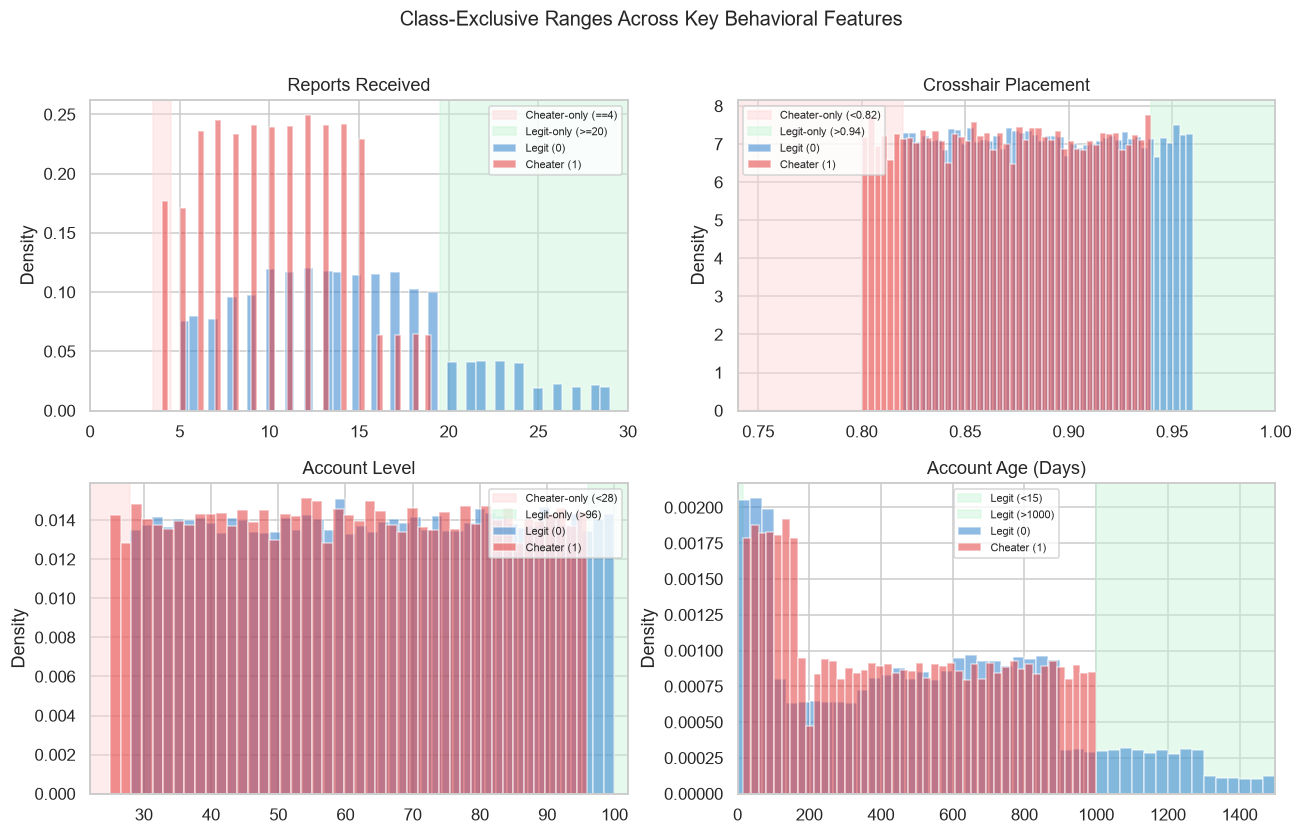

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

specs = [
    ("reports_received", "Reports Received", [(3.5, 4.5, "#fed7d7", "Cheater-only (==4)"), (19.5, 32, "#c6f6d5", "Legit-only (>=20)")], (0, 30)),
    ("crosshair_placement", "Crosshair Placement", [(0.70, 0.82, "#fed7d7", "Cheater-only (<0.82)"), (0.94, 1.0, "#c6f6d5", "Legit-only (>0.94)")], (0.74, 1.0)),
    ("level", "Account Level", [(20, 28, "#fed7d7", "Cheater-only (<28)"), (96, 102, "#c6f6d5", "Legit-only (>96)")], (22, 102)),
    ("account_age_days", "Account Age (Days)", [(0, 15, "#c6f6d5", "Legit (<15)"), (1000, 1550, "#c6f6d5", "Legit (>1000)")], (0, 1500)),
]

for ax, (col, title, zones, xlim) in zip(axes.ravel(), specs):
    for lo, hi, clr, lbl in zones:
        ax.axvspan(lo, hi, color=clr, alpha=0.45, label=lbl)
    ax.hist(lab.loc[y == 0, col].dropna(), bins=45, density=True, alpha=0.55, color="#3182ce", label="Legit (0)")
    ax.hist(lab.loc[y == 1, col].dropna(), bins=45, density=True, alpha=0.55, color="#e53e3e", label="Cheater (1)")
    ax.set_xlim(*xlim)
    ax.set_title(title)
    ax.set_ylabel("Density")
    ax.legend(fontsize=7.5)

plt.suptitle("Class-Exclusive Ranges Across Key Behavioral Features", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**Insight 4**:
- Multiple features contain **100% pure class-exclusive regions** (e.g., `reports_received == 4`, `crosshair_placement < 0.82`, `level < 28` are cheater-only; `reports_received >= 20`, `crosshair_placement > 0.94`, `level > 96`, `account_age_days < 15` or `> 1000` are legit-only), while an overlapping core (~55% of players) drives the main classification difficulty.

**Decision**:
- Engineer explicit `zone_cheat` and `zone_legit` indicator flags plus `age_segment` bins so both tree and non-tree models immediately isolate the pure regions and focus capacity on the overlapping core.

## Step 5: Exact Algebraic Identity (`level_progression_speed = level * r / account_age_days`)

**What we check**: How tightly are `level`, `account_age_days`, and `level_progression_speed` linked?

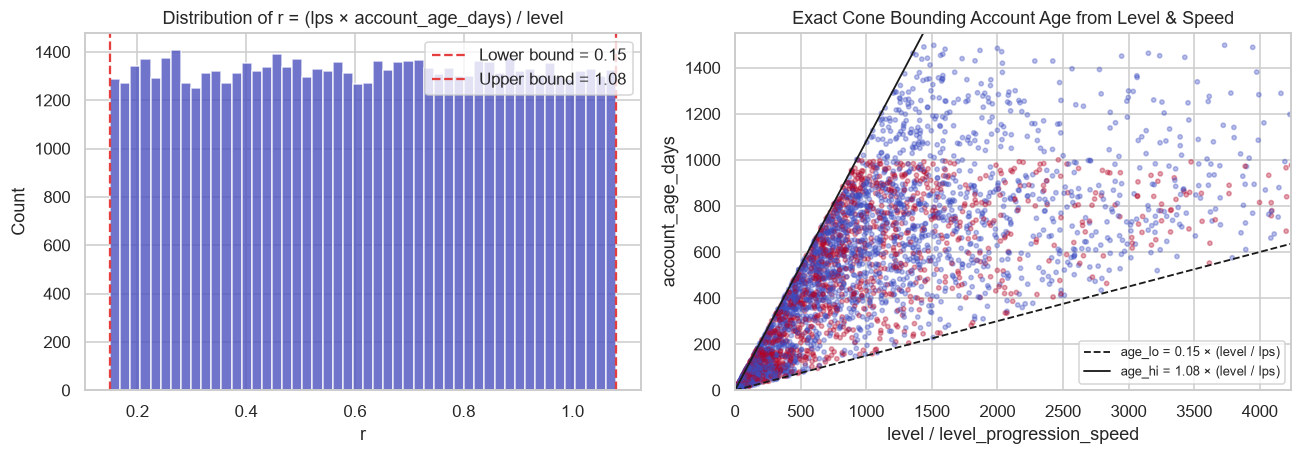

Observed r: min=0.15001, median=0.61603, max=1.07999 (exact Uniform[0.15, 1.08])


In [6]:
r_obs = (lab["level_progression_speed"] * lab["account_age_days"] / lab["level"]).dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

# Panel A: Distribution of r
axes[0].hist(r_obs, bins=50, color="#4c51bf", alpha=0.8, edgecolor="white")
axes[0].axvline(0.15, color="#e53e3e", linestyle="--", lw=1.5, label="Lower bound = 0.15")
axes[0].axvline(1.08, color="#e53e3e", linestyle="--", lw=1.5, label="Upper bound = 1.08")
axes[0].set_title("Distribution of r = (lps × account_age_days) / level")
axes[0].set_xlabel("r")
axes[0].set_ylabel("Count")
axes[0].legend()

# Panel B: Visualising bounds when age is recovered from level / lps
sub = lab[["account_age_days", "level", "level_progression_speed", TARGET]].dropna().sample(4000, random_state=42)
ratio = sub["level"] / sub["level_progression_speed"]
axes[1].scatter(ratio, sub["account_age_days"], c=sub[TARGET], cmap="coolwarm", alpha=0.35, s=8)
xs = np.linspace(0, ratio.quantile(0.98), 100)
axes[1].plot(xs, 0.15 * xs, "k--", lw=1.2, label="age_lo = 0.15 × (level / lps)")
axes[1].plot(xs, 1.08 * xs, "k-", lw=1.2, label="age_hi = 1.08 × (level / lps)")
axes[1].set_xlim(0, ratio.quantile(0.98))
axes[1].set_ylim(0, 1550)
axes[1].set_xlabel("level / level_progression_speed")
axes[1].set_ylabel("account_age_days")
axes[1].set_title("Exact Cone Bounding Account Age from Level & Speed")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

print(f"Observed r: min={r_obs.min():.5f}, median={r_obs.median():.5f}, max={r_obs.max():.5f} (exact Uniform[0.15, 1.08])")

**Insight 5**:
- The ratio $r = \frac{\text{level\_progression\_speed} \times \text{account\_age\_days}}{\text{level}}$ follows an **exact Uniform$(0.15, 1.08)$** distribution with zero exceptions.
- Whenever `account_age_days` is missing (14.5% of rows) or `level` is missing (7.2% of rows), the other two columns bound the missing value inside a tight interval!

**Decision**:
- Compute exact bounds (`age_lo`, `age_hi`, `lv_lo`, `lv_hi`), geometric-mean fills (`age_filled`, `lvl_filled`), and **label-free Bayesian zone posteriors** integrating the empirical training marginal prior over the allowed interval.

---

## Summary: EDA Insights $\rightarrow$ Modeling Decisions (`task1.ipynb`)

| Step | EDA Finding | Decision in `task1.ipynb` |
| :--- | :--- | :--- |
| 1 | 12.7% unlabeled train rows; 34.9% cheater rate; Binary $F_2$ metric | Train supervised models on labeled rows; use all train rows for label-free stats; optimize fixed OOF Binary $F_2$ threshold |
| 2 | 16 of 31 features have AUC $\approx 0.500$ | Drop all 16 noise features; keep 15 signal features |
| 3 | Missing values are MCAR (identical cheater rate when NaN vs. observed) | Apply 4× **MCAR random-masking augmentation** in LightGBM training folds |
| 4 | Pure class-exclusive intervals in reports, crosshair, level, age, friends | Add explicit `zone_cheat`, `zone_legit`, and `age_segment` features |
| 5 | Exact identity `lps = level * r / age` with $r \sim U(0.15, 1.08)$ | Engineer exact missing-value bounds and Bayesian zone posteriors |